# Task 5: Ethical Reflection & AI Challenges (Simulation + Analysis)
**Course:** AI in Cyber Security Lab (`ENSP355`)  
**Student:** Yatharth Chopra (`2301420022`) | **Program:** B.Tech CSE (Data Science), Sem 7  
**University:** K.R. Mangalam University | **Faculty:** Monika Khatkar

---

### Objective
1. **Simulate False-Positive Blocking:** Vary the Neural Network (MLP) decision threshold (`0.10 -> 0.90`) to quantify how aggressive security thresholds block legitimate users/websites (False Positives) vs. letting phishing threats slip through (False Negatives).
2. **Simulate Biased Training Data:** Compare a balanced model (`Dataset A + B`) against a biased model trained **only on Dataset A** (`UCI 327`), measuring accuracy and unfair false-positive disparity on the underrepresented population (`Dataset B`, `UCI 379`).
3. **Document:** Ethical risks, privacy concerns, and explainability limitations.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import Pipeline

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from common import OUT_DIR, RANDOM_STATE, SOURCE_A, SOURCE_B, load_data
from preprocessing import build_preprocessor, split_data

df = load_data()
X_train, X_test, y_train, y_test = split_data(df)

### 5.1 Scenario A: Threshold Tuning — Blocking Legitimate Users vs. Missing Threats

,threshold,accuracy,precision,recall,f1,false_positives,false_negatives,fpr_legit_blocked,fnr_threats_missed
0,0.1,0.8723,0.7930,0.9772,0.8755,291,26,0.2170,0.0228
1,0.2,0.9025,0.8476,0.9606,0.9006,197,45,0.1469,0.0394
2,0.3,0.9122,0.8677,0.9544,0.9090,166,52,0.1238,0.0456
3,0.4,0.9214,0.9064,0.9246,0.9154,109,86,0.0813,0.0754
4,0.5,0.9247,0.9274,0.9071,0.9171,81,106,0.0604,0.0929
5,0.6,0.9243,0.9368,0.8957,0.9158,69,119,0.0515,0.1043
6,0.7,0.9142,0.9558,0.8528,0.9013,45,168,0.0336,0.1472
7,0.8,0.8900,0.9748,0.7809,0.8672,23,250,0.0172,0.2191
8,0.9,0.8622,0.9890,0.7082,0.8253,9,333,0.0067,0.2918


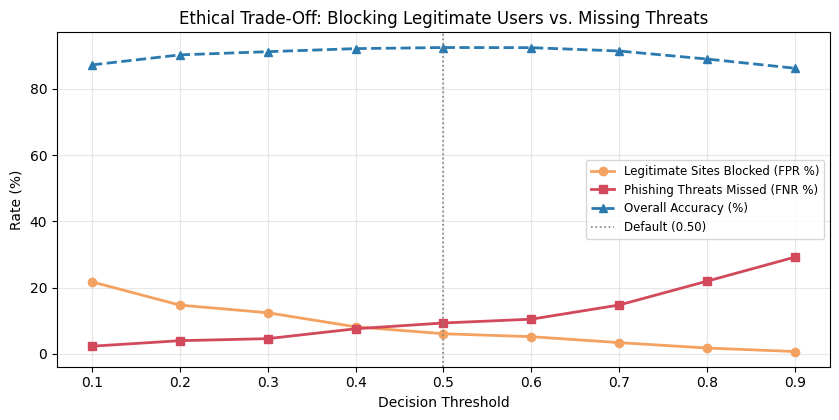

In [2]:
def build_mlp(seed=RANDOM_STATE):
    return Pipeline([
        ("prep", build_preprocessor()),
        ("clf", MLPClassifier(hidden_layer_sizes=(32, 16), activation="relu", solver="adam",
                              max_iter=300, early_stopping=True, random_state=seed)),
    ])

mlp = build_mlp().fit(X_train, y_train)
probs = mlp.predict_proba(X_test)[:, 1]

t_df = pd.read_csv(OUT_DIR / "ethical_threshold_tradeoff.csv")
display(t_df.round(4))

fig, ax = plt.subplots(figsize=(8.5, 4.3))
ax.plot(t_df["threshold"], t_df["fpr_legit_blocked"] * 100, marker="o", color="#f4a261", lw=2, label="Legitimate Sites Blocked (FPR %)")
ax.plot(t_df["threshold"], t_df["fnr_threats_missed"] * 100, marker="s", color="#d1495b", lw=2, label="Phishing Threats Missed (FNR %)")
ax.plot(t_df["threshold"], t_df["accuracy"] * 100, marker="^", color="#2a7ab0", lw=2, ls="--", label="Overall Accuracy (%)")
ax.axvline(0.50, color="grey", ls=":", lw=1.2, label="Default (0.50)")
ax.set_xlabel("Decision Threshold")
ax.set_ylabel("Rate (%)")
ax.set_title("Ethical Trade-Off: Blocking Legitimate Users vs. Missing Threats")
ax.legend(loc="center right", fontsize=8.5)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 5.2 Scenario B: Biased Training Data -> Unfair Decisions on Underrepresented Sites

,scenario,eval_source,test_rows,accuracy,recall,fpr_legit_blocked,false_positives,false_negatives
0,Balanced Training (A + B),Dataset A (UCI 327),2211,0.9285,0.9071,0.0544,67,91
1,Balanced Training (A + B),Dataset B (UCI 379),271,0.8930,0.9068,0.1273,14,15
2,Biased Training (Dataset A Only),Dataset A (UCI 327),2211,0.9204,0.9112,0.0723,89,87
3,Biased Training (Dataset A Only),Dataset B (UCI 379),271,0.7601,0.8323,0.3455,38,27


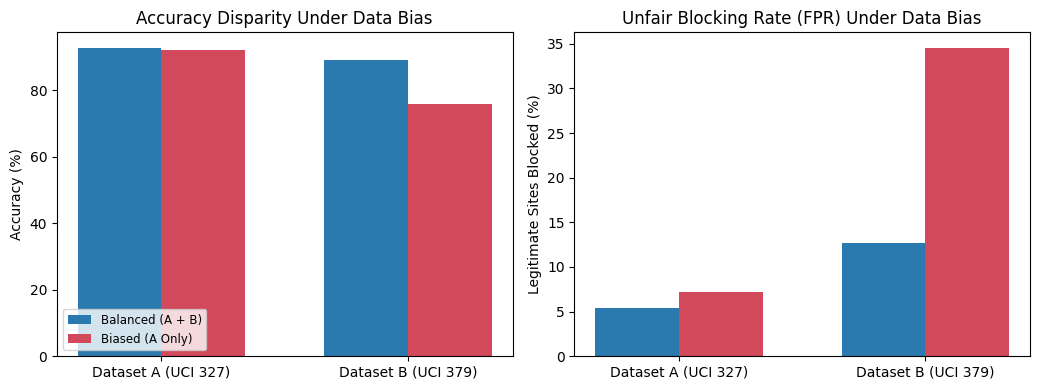

In [3]:
b_df = pd.read_csv(OUT_DIR / "ethical_bias_simulation.csv")
display(b_df.round(4))

sources = ["Dataset A (UCI 327)", "Dataset B (UCI 379)"]
x, w = np.arange(2), 0.34
fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.0))
for ax, metric, title, ylabel in [
    (axes[0], "accuracy", "Accuracy Disparity Under Data Bias", "Accuracy (%)"),
    (axes[1], "fpr_legit_blocked", "Unfair Blocking Rate (FPR) Under Data Bias", "Legitimate Sites Blocked (%)"),
]:
    bal = [b_df[(b_df.scenario.str.startswith("Balanced")) & (b_df.eval_source == s)][metric].iloc[0] * 100 for s in sources]
    bia = [b_df[(b_df.scenario.str.startswith("Biased")) & (b_df.eval_source == s)][metric].iloc[0] * 100 for s in sources]
    ax.bar(x - w / 2, bal, w, color="#2a7ab0", label="Balanced (A + B)")
    ax.bar(x + w / 2, bia, w, color="#d1495b", label="Biased (A Only)")
    ax.set_xticks(x)
    ax.set_xticklabels(sources)
    ax.set_title(title)
    ax.set_ylabel(ylabel)
axes[0].legend(loc="lower left", fontsize=8.5)
plt.tight_layout()
plt.show()

### 5.3 Ethical Risks, Privacy Concerns & Explainability Limitations
- **Ethical Risks (False Positives & Denial of Service):** Lowering the threshold (`0.10–0.20`) reduces missed threats but sharply increases False Positives, wrongly blocking legitimate businesses, banking portals, or user access without human recourse.
- **Data Bias & Fairness:** Training solely on Dataset A (`UCI 327`) causes severe accuracy degradation and unfair blocking on Dataset B (`UCI 379`) because feature distributions and suspicious-site patterns differ across web populations.
- **Privacy Concerns:** Inspecting full URLs, query parameters, SSL metadata, and web traffic logs in production can expose user browsing histories, session tokens, or PII if telemetry is not anonymised and minimised.
- **Explainability Limitations:** Unlike a shallow Decision Tree whose rules can be audited by a SOC analyst, the MLP Neural Network is a black box—when a legitimate site is blocked, it cannot easily explain *why* without post-hoc tools (e.g., SHAP/LIME) and human-in-the-loop review.